<div align="center">

<h1> <b> ENERGÍA Y CAMPO EFECTIVO MICROMAGNÉTICOS DE UN SKYRMION DE BLOCH </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Camilo Vergara Restrepo</b> <br>
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>


---

## 1. Objetivo y contexto

En una película delgada de un material helimagnético (parámetros típicos del FeGe), una textura tipo skyrmion resulta del balance entre el intercambio, la interacción de Dzyaloshinskii-Moriya (DMI), la anisotropía uniaxial y el campo aplicado. Este notebook muestra cómo cada término de la energía micromagnética se escribe como una operación entre campos discretizados (producto punto, producto cruz, laplaciano y rotacional) y comprueba que esas expresiones reproducen la densidad de energía, la energía total y el campo efectivo que calcula el solver OOMMF a través de Ubermag (Beg et al., 2022; Donahue & Porter, 1999).

Con las mismas expresiones se construye después un integrador de la ecuación de Landau-Lifshitz con solo el término de amortiguamiento, que lleva el estado inicial hacia el mínimo de energía. El ejemplo parte del cuaderno *Field operations 2* de la documentación de Ubermag (Ubermag developers, s. f.). Las operaciones de cálculo de las celdas de código son las del ejemplo; cambia la presentación. Las celdas llevan comentarios, las tres comprobaciones de cada término (densidad, energía y campo efectivo) se reúnen en una celda y se imprimen con `print`, sin el error relativo de la energía, y la figura del estado relajado es más grande. En la sección 6 se reutilizan la malla, los parámetros y la función `m_initial` de la sección 3 en lugar de definirlos otra vez con los mismos valores, se omite la gráfica del estado inicial y la variable del bucle se llama `m_orient`, de modo que `m` conserva el estado relajado.

El desarrollo sigue este orden: fundamentos del modelo, definición y relajación del sistema, verificación término a término (Zeeman, anisotropía uniaxial, intercambio y DMI), integración explícita de la dinámica y una comparación con el enfoque de MuMax3.

## 2. Fundamentos físicos

### 2.1 Modelo micromagnético

En la aproximación micromagnética la magnetización es un campo continuo $\mathbf M(\mathbf r,t)=M_s\,\mathbf m(\mathbf r,t)$ de módulo constante $M_s$, de modo que $|\mathbf m|=1$ (Brown, 1963; Aharoni, 2000). La energía es un funcional del campo $\mathbf m$:

$$E[\mathbf m]=\int_V w\,dV,\qquad
w=\underbrace{-A\,\mathbf m\cdot\nabla^2\mathbf m}_{\text{intercambio}}
+\underbrace{D\,\mathbf m\cdot(\nabla\times\mathbf m)}_{\text{DMI (clase T)}}
+\underbrace{K\,|\mathbf m\times\mathbf u|^2}_{\text{anisotropía uniaxial}}
\underbrace{-\mu_0 M_s\,\mathbf m\cdot\mathbf H}_{\text{Zeeman}} .$$

Para un campo unitario se cumple $\mathbf m\cdot\partial_k\mathbf m=0$ y, derivando de nuevo, $\mathbf m\cdot\nabla^2\mathbf m=-|\nabla\mathbf m|^2$. Por eso la densidad de intercambio escrita arriba coincide con la forma usual $A|\nabla\mathbf m|^2$. Este sistema no incluye el término magnetostático (campo desmagnetizante), lo que hace que todos los términos sean locales y puedan escribirse con derivadas de $\mathbf m$.

### 2.2 Campo efectivo y dinámica

El campo efectivo se define como la derivada funcional de la energía,

$$\mathbf H_\mathrm{eff}=-\frac{1}{\mu_0 M_s}\frac{\delta E}{\delta\mathbf m},$$

y la dinámica obedece la ecuación de Landau-Lifshitz-Gilbert en su forma de Landau-Lifshitz (Landau & Lifshitz, 1935; Gilbert, 2004):

$$\frac{d\mathbf m}{dt}=-\frac{\gamma_0}{1+\alpha^2}\Big[\mathbf m\times\mathbf H_\mathrm{eff}+\alpha\,\mathbf m\times(\mathbf m\times\mathbf H_\mathrm{eff})\Big],$$

con $\gamma_0\approx2.211\times10^{5}\ \mathrm{m\,A^{-1}s^{-1}}$ y $\alpha$ el parámetro de amortiguamiento. Un estado estático cumple $\mathbf m\times\mathbf H_\mathrm{eff}=\mathbf 0$ en todo punto, y el estado estable es un mínimo de $E$.

### 2.3 Discretización

Ubermag describe el problema sobre una malla regular de celdas cúbicas y OOMMF resuelve con diferencias finitas. Las integrales se convierten en sumas $\sum_i w_i\,\Delta V$ y las derivadas espaciales en diferencias entre celdas vecinas. La película del ejemplo tiene $20\times20\times1$ celdas de 5 nm, con condiciones periódicas en $x$ e $y$, por lo que en la práctica es un problema bidimensional en el que cada celda interactúa con cuatro vecinas.

### 2.4 Escalas características

Con $A=8.78\times10^{-12}$ J/m, $D=1.58\times10^{-3}$ J/m², $K=10^{4}$ J/m³ y $M_s=3.84\times10^{5}$ A/m resultan:

| Magnitud | Expresión | Valor |
|---|---|---|
| Longitud de intercambio | $\ell_\mathrm{ex}=\sqrt{2A/(\mu_0M_s^2)}$ | 9.7 nm |
| Periodo de la hélice por DMI | $L_D=4\pi A/\lvert D\rvert$ | 69.8 nm |
| Campo de anisotropía | $H_K=2K/(\mu_0M_s)$ | $4.1\times10^{4}$ A/m |
| Campo aplicado | $\mu_0H$ | 0.126 T |

El tamaño de celda (5 nm) es menor que $\ell_\mathrm{ex}$, requisito habitual para que el intercambio esté bien resuelto, y el periodo $L_D$ está dentro del orden de la caja de 100 nm, de modo que cabe una modulación quiral completa. El periodo helicoidal $4\pi A/|D|$ proviene de la competencia entre intercambio y DMI (Bak & Jensen, 1980).

## 3. Sistema, parámetros y relajación

La celda siguiente importa los tres paquetes de Ubermag que se usan: `discretisedfield` (campos sobre mallas y sus operaciones), `micromagneticmodel` (descripción del problema físico) y `oommfc` (calculadora que delega en OOMMF). La región es una película de $100\times100\times5$ nm$^3$ con celdas de 5 nm; `bc="xy"` impone periodicidad en $x$ e $y$.

La energía del sistema se declara sumando objetos `Exchange`, `DMI`, `Zeeman` y `UniaxialAnisotropy`. La opción `crystalclass="T"` corresponde a la DMI de volumen, con densidad $D\,\mathbf m\cdot(\nabla\times\mathbf m)$, que favorece giros de la magnetización con quiralidad fija y, en este caso, texturas de tipo Bloch (Bogdanov & Hubert, 1994; Rößler et al., 2006).

El estado inicial es un disco de radio $L/4=25$ nm con $\mathbf m=-\hat z$ rodeado de $\mathbf m=+\hat z$; el argumento `norm=Ms` hace que el campo guarde $\mathbf M$ en A/m. `MinDriver` minimiza la energía a partir de ese estado, por defecto con un método de gradiente conjugado de OOMMF, y la última línea grafica la componente $z$ (color) y la proyección en el plano (flechas).

Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:06:59]... (6.1 s)


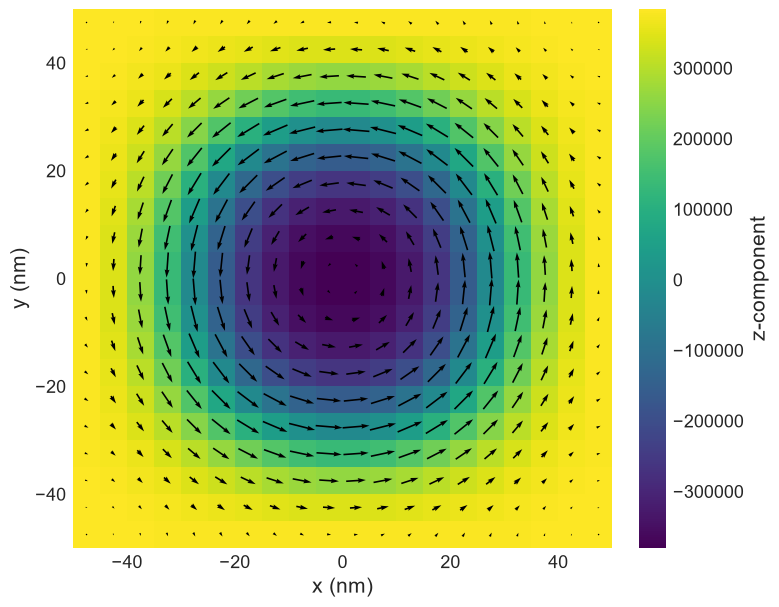

In [1]:
# =========================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN DEL SISTEMA
# =========================================================================
# Usamos discretisedfield para representar el espacio tridimensional y realizar
# operaciones matemáticas (gradiente, rotacional, laplaciano) sobre la magnetización.
import discretisedfield as df

# micromagneticmodel nos permite definir las reglas físicas del material
# (las energías involucradas y la dinámica de los espines).
import micromagneticmodel as mm

# oommfc es el puente o interfaz que traduce nuestro código Python al simulador
# OOMMF para resolver las ecuaciones micromagnéticas en segundo plano.
import oommfc as mc

# =========================================================================
# 2. DEFINICIÓN DE LA GEOMETRÍA Y LA MALLA DE DISCRETIZACIÓN
# =========================================================================
# Los skyrmions son estructuras magnéticas del orden de los nanómetros.
# Creamos una película delgada de 100 nm x 100 nm con 5 nm de espesor,
# un espacio confinado ideal para albergar y aislar este tipo de texturas.
L = 100e-9
thickness = 5e-9

# Para que la computadora pueda procesar el problema, dividimos la muestra en cubos.
# Cada celda medirá 5 nm. Físicamente, este tamaño debe ser inferior a la longitud
# de intercambio (l_ex ≈ 9.7 nm) para asegurar que el simulador capture de forma precisa
# las transiciones y giros suaves entre espines vecinos sin perder resolución física.
cell = (5e-9, 5e-9, 5e-9)

# Definimos los puntos extremos opuestos que delimitan nuestra caja tridimensional.
p1 = (-L / 2, -L / 2, 0)
p2 = (L / 2, L / 2, thickness)

# Construimos la región física y la subdividimos con la malla espacial.
# Usamos bc="xy" (condiciones de frontera periódicas) para que los bordes izquierdo-derecho
# y superior-inferior estén interconectados. Esto simula un material infinito y permite
# la formación natural de una red ordenada de skyrmions sin efectos perturbadores de borde.
region = df.Region(p1=p1, p2=p2)
mesh = df.Mesh(region=region, cell=cell, bc="xy")

# =========================================================================
# 3. PARÁMETROS FÍSICOS DEL MATERIAL (TÍPICOS DE FeGe)
# =========================================================================
# Aquí configuramos la identidad del material (en este caso, germaniuro de hierro, FeGe):
Ms = 3.84e5              # Magnetización de saturación: cantidad total de momento magnético disponible por unidad de volumen.
A = 8.78e-12             # Constante de intercambio: la fuerza que obliga a los espines vecinos a alinearse paralelos entre sí.
D = 1.58e-3              # Constante de Dzyaloshinskii-Moriya (DMI): interacción quiral que prefiere que los espines se tuerzan a 90°.
K = 1e4                  # Anisotropía uniaxial: la energía de preferencia que premia a los espines por alinearse en una dirección específica.
u = (0, 0, 1)            # Eje fácil de anisotropía: definimos que la dirección preferida de alineación sea el eje vertical (Z).
H = (0, 0, 1e5)          # Campo magnético externo: fuerza magnética constante aplicada en dirección vertical (+Z) para estabilizar la estructura.

# =========================================================================
# 4. CONSTRUCCIÓN DEL MODELO FÍSICO
# =========================================================================
# Creamos el objeto principal del sistema y añadimos todos los términos de energía
# que competirán entre sí: el intercambio busca orden uniforme, la DMI favorece
# el giro quiral, el campo Zeeman empuja los espines hacia arriba y la anisotropía
# los sujeta a la vertical. De este balance competitivo nacerá el skyrmion.
system = mm.System(name="skyrmion")
system.energy = (
    mm.Exchange(A=A)
    + mm.DMI(D=D, crystalclass="T")          # DMI clase T para inducir una rotación espiral tipo Bloch (skyrmion de Bloch).
    + mm.Zeeman(H=H)
    + mm.UniaxialAnisotropy(K=K, u=u)
)

# =========================================================================
# 5. ESTADO INICIAL (SEMILLA CON UN DISCO INVERTIDO)
# =========================================================================
# Para facilitar la formación del skyrmion, sembramos una perturbación local:
# un disco central de radio L/4 (25 nm) donde los momentos magnéticos apuntan hacia abajo (-Z),
# rodeado por una matriz externa donde todos apuntan hacia arriba (+Z).
def m_initial(point):
    x, y, z = point
    if x**2 + y**2 < (L / 4) ** 2:
        return (0, 0, -1)
    else:
        return (0, 0, 1)

# Inicializamos el campo magnético en la malla. La normalización (norm=Ms)
# garantiza que, independientemente de la dirección, la magnitud de la magnetización
# sea exactamente Ms en cada celda, respetando la física de espines de módulo constante.
system.m = df.Field(mesh, nvdim=3, value=m_initial, norm=Ms)

# =========================================================================
# 6. RELAJACIÓN ENERGÉTICA (BÚSQUEDA DEL MÍNIMO DE ENERGÍA)
# =========================================================================
# Iniciamos el motor de simulación de OOMMF utilizando un algoritmo de minimización.
# Este deforma paulatinamente la distribución inicial de espines como si fuera una membrana
# elástica hasta alcanzar un mínimo local de la energía: el skyrmion estable.
md = mc.MinDriver()
md.drive(system)

# Extraemos y graficamos la componente Z de la magnetización final para observar
# el perfil del skyrmion resultante y el sentido de giro de sus espines en el plano.
system.m.sel("z").mpl(figsize=(9, 7))

La textura relajada es un skyrmion de Bloch: $m_z$ pasa de $-M_s$ en el núcleo a $+M_s$ en el exterior, y las flechas del plano circulan alrededor del núcleo (la componente en el plano es perpendicular a la dirección radial), como corresponde a una DMI de volumen. Como la caja es periódica y mide 100 nm, la solución equivale a una red cuadrada de skyrmions de ese periodo, no a un objeto aislado. El resultado depende del campo, de $K$ y del tamaño de la caja: el estado uniforme saturado también es un equilibrio, y la relajación converge a un equilibrio con la simetría del disco inicial. La sección 8.2 muestra que ese equilibrio no es un mínimo: frente a una deformación elíptica es un punto de silla.

## 4. Magnetización reducida

Todas las expresiones de energía se escriben con $\mathbf m=\mathbf M/M_s$, y los factores $M_s$ aparecen explícitamente donde corresponde. `system.m.orientation` devuelve el campo normalizado (módulo 1, adimensional), y `clim=(-1, 1)` fija la escala de color a todo el rango posible de $m_z$.

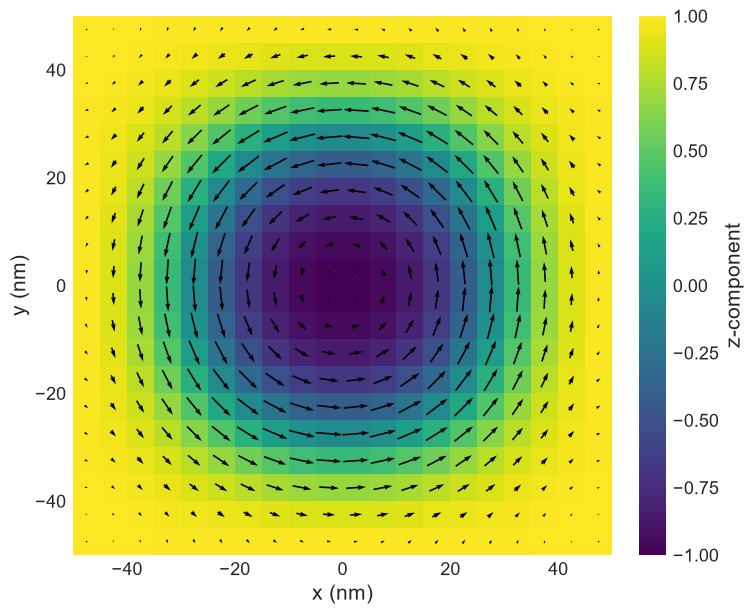

In [2]:
# =========================================================================
# EXTRACCIÓN DEL CAMPO DE MAGNETIZACIÓN REDUCIDA (m)
# =========================================================================
# En física micromagnetica es sumamente práctico trabajar de forma adimensional.
# Dividimos el vector de magnetización M entre su módulo de saturación Ms (m = M / Ms).
# Esto genera un campo vectorial 'm' donde cada vector tiene longitud exacta de 1,
# simplificando las ecuaciones matemáticas al independizarlas de la escala del material.
m = system.m.orientation

# Graficamos la componente Z de esta magnetización reducida.
# Al fijar 'clim': (-1, 1), obligamos al mapa de colores a abarcar simétricamente
# los límites de los espines: -1 representa el núcleo apuntando completamente hacia abajo (violeta oscuro)
# y 1 representa el exterior orientado hacia arriba (amarillo).
m.sel("z").mpl(scalar_kw={'clim': (-1, 1)}, figsize=(9, 7))

## 5. Verificación término a término

Para cada término se comparan dos rutas de cálculo sobre el mismo estado relajado. En la ruta `df` la expresión se evalúa con operaciones de `discretisedfield` (`dot`, `cross`, `laplace`, `curl`, `integrate`). En la ruta `mc` se llama a `mc.compute`, que ejecuta OOMMF sobre ese estado y devuelve la densidad de energía, la energía o el campo efectivo del término correspondiente. Se verifican tres cosas por término:

1. la densidad de energía $w(\mathbf r)$, con `allclose` sobre todo el campo;
2. la energía total $E=\int w\,dV$, con `integrate()` frente a la energía de OOMMF;
3. el campo efectivo $\mathbf H_\mathrm{eff}$ (en A/m), con `allclose`.

Cada `mc.compute` lanza una ejecución de OOMMF, de ahí que cada celda imprima una línea `Running OOMMF` por comparación.

### 5.1 Término Zeeman

$$w_Z=-\mu_0M_s\,\mathbf m\cdot\mathbf H,\qquad E_Z=-\mu_0M_s\int_V\mathbf m\cdot\mathbf H\,dV,\qquad
\mathbf H_\mathrm{eff}^{Z}=-\frac{1}{\mu_0M_s}\frac{\delta}{\delta\mathbf m}\big(-\mu_0M_s\,\mathbf m\cdot\mathbf H\big)=\mathbf H .$$

La energía es mínima cuando $\mathbf m\parallel\mathbf H$ y el campo efectivo es el propio campo aplicado, uniforme. En el código, `m.dot(H)` es el producto punto punto a punto entre el campo $\mathbf m$ y el vector constante $\mathbf H=(0,0,10^5)$ A/m.

Con $\mathbf m=+\hat z$ en toda la película resultaría $E_Z=-\mu_0M_sHV\approx-2.41\times10^{-18}$ J, con $V=5\times10^{-23}$ m$^3$. El valor obtenido, $-1.03\times10^{-18}$ J, corresponde a una magnetización media $\langle m_z\rangle=E_Z/(-\mu_0M_sHV)\approx0.43$, coherente con un núcleo de $m_z<0$ que ocupa una fracción apreciable de la caja.

In [3]:
# =========================================================================
# VERIFICACIÓN DEL TÉRMINO ZEEMAN
# =========================================================================
# El término Zeeman cuantifica la interacción del material con un campo magnético externo.
# Su objetivo es alinear los momentos magnéticos en la dirección del campo aplicado.

# 1. Densidad de Energía (w_Z = -mu_0 * Ms * m · H):
# Calculamos el costo energético local en cada punto usando el producto punto
# de la magnetización y el campo. Es mínimo (favorable) cuando están perfectamente alineados.
wdf = -mm.consts.mu0 * Ms * m.dot(H)
# Comparamos nuestro cálculo directo de diferencias finitas con el valor devuelto por OOMMF.
wmc = mc.compute(system.energy.zeeman.density, system)
print("Zeeman density check:", wdf.allclose(wmc))

# 2. Energía Total (E_Z = integral de w_Z dv):
# Sumamos la densidad de energía multiplicada por el volumen de cada celda sobre toda la muestra.
# Un valor neto negativo nos indica estabilidad frente al campo externo.
Edf = (-mm.consts.mu0 * Ms * m.dot(H)).integrate()
Emc = mc.compute(system.energy.zeeman.energy, system)
print(f"Energy df: {Edf} | mc: {Emc}")

# 3. Campo efectivo
Hdf = df.Field(mesh, nvdim=3, value=H)
Hmc = mc.compute(system.energy.zeeman.effective_field, system)
print("Zeeman Heff check:", Hdf.allclose(Hmc))

Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:05]... (6.1 s)
Zeeman density check: True
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:12]... (6.2 s)
Energy df: [-1.03472186e-18] | mc: -1.03472185973e-18
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:18]... (6.1 s)
Zeeman Heff check: True


### 5.2 Anisotropía uniaxial

$$w_K=K\,|\mathbf m\times\mathbf u|^2=K\big[1-(\mathbf m\cdot\mathbf u)^2\big],\qquad
\mathbf H_\mathrm{eff}^{K}=\frac{2K}{\mu_0M_s}(\mathbf m\cdot\mathbf u)\,\mathbf u .$$

Con $K>0$ el eje $\mathbf u=\hat z$ es de fácil magnetización: la energía se anula para $\mathbf m=\pm\hat z$ y es máxima en el plano. La igualdad entre ambas formas de $w_K$ usa $|\mathbf m|=|\mathbf u|=1$. El código calcula $|\mathbf m\times\mathbf u|^2$ como el producto punto de `abs(m.cross(u))` consigo mismo. Algunos códigos escriben esta densidad como $-K(\mathbf m\cdot\mathbf u)^2$ (por ejemplo MuMax3, o la ecuación de energía de Holt et al., 2025). Las dos formas difieren en la constante $K$ por unidad de volumen, que no afecta al campo efectivo ni a la dinámica, pero sí al valor absoluto de la energía en $K\,V$.

El campo de anisotropía $H_K=2K/(\mu_0M_s)\approx4.1\times10^4$ A/m es menor que el campo aplicado ($10^5$ A/m), así que el término Zeeman domina sobre la anisotropía en el exterior del skyrmion.

In [4]:
# =========================================================================
# VERIFICACIÓN DEL TÉRMINO DE ANISOTROPÍA UNIAXIAL
# =========================================================================

# 1. Densidad de Energía: w_K = K * |m x u|^2
# Se obtiene calculando la componente perpendicular al eje fácil Z.
wdf = K * abs(m.cross(u)).dot(abs(m.cross(u)))
wmc = mc.compute(system.energy.uniaxialanisotropy.density, system)
print("Uniaxial density check:", wdf.allclose(wmc))

# 2. Energía Total: E_K = integral de w_K dv
# Se cuantifica el coste energético en las paredes donde la magnetización se aleja del eje Z.
Edf = (K * abs(m.cross(u)).dot(abs(m.cross(u)))).integrate()
Emc = mc.compute(system.energy.uniaxialanisotropy.energy, system)
print(f"Energy df: {Edf} | mc: {Emc}")

# 3. Campo Efectivo de Anisotropía: H_eff^K = [2K / (mu_0 * Ms)] * (m · u) * u
# Este término actúa orientando los momentos magnéticos hacia el eje fácil.
Hdf = 2 * K / (mm.consts.mu0 * Ms) * (m.dot(u)) * u
Hmc = mc.compute(system.energy.uniaxialanisotropy.effective_field, system)
print("Uniaxial Heff check:", Hdf.allclose(Hmc))

Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:24]... (6.2 s)
Uniaxial density check: True
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:30]... (6.1 s)
Energy df: [2.0433559e-19] | mc: 2.04335590124e-19
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:36]... (6.2 s)
Uniaxial Heff check: True


### 5.3 Intercambio

$$w_\mathrm{ex}=-A\,\mathbf m\cdot\nabla^2\mathbf m=A\,|\nabla\mathbf m|^2,\qquad
\mathbf H_\mathrm{eff}^\mathrm{ex}=\frac{2A}{\mu_0M_s}\nabla^2\mathbf m .$$

El intercambio de Heisenberg, en el límite continuo, penaliza las variaciones espaciales de $\mathbf m$ con constante de rigidez $A$. Es nulo para una magnetización uniforme y positivo en una textura. La derivada funcional de $A|\nabla\mathbf m|^2$ es $-2A\nabla^2\mathbf m$, de donde sale el factor del campo efectivo. En la malla, `m.laplace` suma diferencias segundas entre celdas vecinas (con periodicidad en $x$ e $y$). Con una sola celda en $z$ no hay variación a lo largo del espesor.

La energía obtenida, $+1.74\times10^{-18}$ J, es el costo de la curvatura del skyrmion.

In [5]:
# =========================================================================
# VERIFICACIÓN DEL TÉRMINO DE INTERCAMBIO (EXCHANGE)
# =========================================================================

# 1. Densidad de Energía: w_ex = -A * m · grad^2(m)
# Estimamos la variación espacial local empleando el operador Laplaciano por diferencias finitas.
wdf = -A * m.dot(m.laplace)
wmc = mc.compute(system.energy.exchange.density, system)
print("Exchange density check:", wdf.allclose(wmc))

# 2. Energía Total de Intercambio: E_ex = integral de w_ex dv
# Representa el costo energético acumulado por la distorsión del alineamiento paralelo.
Edf = (-A * m.dot(m.laplace)).integrate()
Emc = mc.compute(system.energy.exchange.energy, system)
print(f"Energy df: {Edf} | mc: {Emc}")

# 3. Campo Efectivo de Intercambio: H_eff^ex = [2A / (mu_0 * Ms)] * grad^2(m)
# Campo restaurador que tiende a homogeneizar la orientación local de los espines.
Hdf = 2 * A / (mm.consts.mu0 * Ms) * m.laplace
Hmc = mc.compute(system.energy.exchange.effective_field, system)
print("Exchange Heff check:", Hdf.allclose(Hmc))

Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:42]... (6.1 s)
Exchange density check: True
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:49]... (6.1 s)
Energy df: [1.74383742e-18] | mc: 1.74383742383e-18
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:07:55]... (6.2 s)
Exchange Heff check: True


### 5.4 Interacción de Dzyaloshinskii-Moriya (clase T)

$$w_\mathrm{DMI}=D\,\mathbf m\cdot(\nabla\times\mathbf m),\qquad
\mathbf H_\mathrm{eff}^\mathrm{DMI}=-\frac{2D}{\mu_0M_s}\,(\nabla\times\mathbf m).$$

La DMI es un intercambio antisimétrico que resulta del acoplamiento espín-órbita en redes sin centro de inversión (Dzyaloshinsky, 1958; Moriya, 1960). En cristales de la clase T, como los compuestos B20, su forma continua es el invariante de Lifshitz $\mathbf m\cdot(\nabla\times\mathbf m)$, que favorece una rotación de $\mathbf m$ con quiralidad fija y es la base de las hélices y de las redes de skyrmions de estos materiales (Bak & Jensen, 1980; Mühlbauer et al., 2009).

Con una sola celda en $z$ las derivadas $\partial_z$ son nulas y el rotacional se reduce a $(\partial_ym_z,\,-\partial_xm_z,\,\partial_xm_y-\partial_ym_x)$, de modo que

$$w_\mathrm{DMI}=D\big[m_x\partial_ym_z-m_y\partial_xm_z+m_z(\partial_xm_y-\partial_ym_x)\big].$$

La energía obtenida, $-4.35\times10^{-18}$ J, es negativa: la DMI reduce la energía cuando la magnetización gira con la quiralidad favorecida. El signo de $D$ fija la quiralidad del skyrmion.

In [6]:
# =========================================================================
# VERIFICACIÓN DEL TÉRMINO DMI (CLASE T)
# =========================================================================

# 1. Densidad de Energía: w_DMI = D * m · (rotacional de m)
# Evaluamos el rotacional del campo para cuantificar la quiralidad del acoplamiento.
wdf = D * m.dot(m.curl)
wmc = mc.compute(system.energy.dmi.density, system)
print("DMI density check:", wdf.allclose(wmc))

# 2. Energía Total DMI: E_DMI = integral de w_DMI dv
# Esta ganancia de energía negativa compensa el coste de intercambio y estabiliza el skyrmion.
Edf = (D * m.dot(m.curl)).integrate()
Emc = mc.compute(system.energy.dmi.energy, system)
print(f"Energy df: {Edf} | mc: {Emc}")

# 3. Campo Efectivo DMI: H_eff^DMI = - [2D / (mu_0 * Ms)] * (rotacional de m)
# Determina la quiralidad favoreciendo giros perpendiculares de los momentos magnéticos vecinos.
Hdf = -2 * D / (mm.consts.mu0 * Ms) * m.curl
Hmc = mc.compute(system.energy.dmi.effective_field, system)
print("DMI Heff check:", Hdf.allclose(Hmc))

Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:08:01]... (6.2 s)
DMI density check: True
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:08:07]... (6.1 s)
Energy df: [-4.35058832e-18] | mc: -4.35058832403e-18
Running OOMMF (ExeOOMMFRunner)[2026-10-29T15:08:13]... (6.2 s)
DMI Heff check: True


### 5.5 Balance energético

Las cuatro energías impresas suman $E\approx-3.44\times10^{-18}$ J. El estado uniforme $\mathbf m=+\hat z$ tiene $E=-\mu_0M_sHV\approx-2.41\times10^{-18}$ J (los demás términos se anulan), de modo que a este campo la textura relajada tiene una energía menor que la del estado saturado en unos $1.0\times10^{-18}$ J. Dentro de esa textura, el costo de intercambio ($+1.74\times10^{-18}$ J) queda más que compensado por la ganancia de DMI ($-4.35\times10^{-18}$ J), y es la anisotropía, que aporta solo $+2.0\times10^{-19}$ J, el término menor.

Las energías de OOMMF y de `discretisedfield` coinciden hasta la precisión impresa (8 a 9 cifras significativas), porque ambas operan sobre exactamente el mismo estado discretizado y usan las mismas expresiones en diferencias finitas.

## 6. Integración explícita de la dinámica de relajación

Las funciones de la celda siguiente implementan el mismo modelo con operaciones de campos. `Heff_function` suma los cuatro campos efectivos de la sección 5, en A/m:

$$\mathbf H_\mathrm{eff}=\frac{2A}{\mu_0M_s}\nabla^2\mathbf m-\frac{2D}{\mu_0M_s}\nabla\times\mathbf m+\frac{2K}{\mu_0M_s}(\mathbf m\cdot\mathbf u)\mathbf u+\mathbf H .$$

`dmdt_function` conserva solo el término de amortiguamiento de la ecuación de Landau-Lifshitz,

$$\frac{d\mathbf m}{dt}=-\frac{\gamma_0\alpha}{1+\alpha^2}\,\mathbf m\times(\mathbf m\times\mathbf H_\mathrm{eff}),$$

lo que elimina la precesión y acelera la relajación. Como $\mathbf m\times(\mathbf m\times\mathbf H)=-\mathbf H_\perp$, este término empuja a $\mathbf m$ hacia $\mathbf H_\mathrm{eff}$ y hace que la energía disminuya monótonamente en el límite de paso pequeño:

$$\frac{dE}{dt}=-\mu_0M_s\,\frac{\gamma_0\alpha}{1+\alpha^2}\int_V|\mathbf m\times\mathbf H_\mathrm{eff}|^2\,dV\le0 .$$

La integración es de Euler explícito, $\mathbf m_{n+1}=\mathbf m_n+\Delta t\,\dot{\mathbf m}(\mathbf m_n)$, con $T=0.1$ ns, $n=100$ pasos y $\Delta t=1$ ps. Tras cada paso el campo se reconstruye con `norm=Ms`, lo que reimpone $|\mathbf M|=M_s$ (un paso de Euler no conserva el módulo). El bucle es secuencial porque el estado $n+1$ depende del estado $n$. A diferencia de la sección 3, la integración parte del disco inicial y no del estado relajado.

El esquema es condicionalmente estable. El modo de mayor frecuencia espacial del laplaciano en 2D (un tablero de ajedrez) tiene autovalor $-8/\Delta^2$, y la tasa de decaimiento asociada es $\lambda=\frac{\gamma_0\alpha}{1+\alpha^2}\frac{2A}{\mu_0M_s}\frac{8}{\Delta^2}\approx1.3\times10^{12}\ \mathrm{s^{-1}}$ con $\Delta=5$ nm. Euler exige $\lambda\Delta t<2$, y aquí $\lambda\Delta t\approx1.3$: el paso usado es estable pero cercano al límite, y un paso mayor haría divergir los modos de alta frecuencia. Esta estimación es de orden de magnitud y solo considera el intercambio.

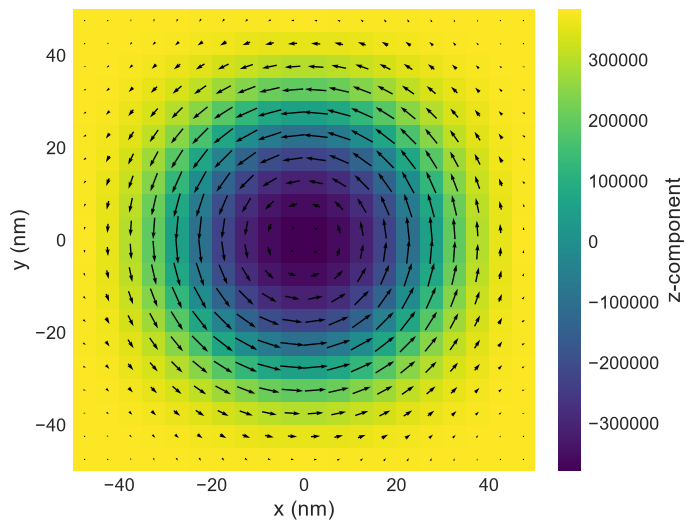

In [7]:
# =========================================================================
# DYNAMICS INTEGRATION: IMPLEMENTACIÓN NUMÉRICA DE LA ECUACIÓN DE LLG
# =========================================================================
import numpy as np

# Parámetro de amortiguamiento crítico para guiar rápidamente al sistema al equilibrio.
alpha = 1

# 1. Campo Efectivo Total (H_eff)
# Suma lineal de las contribuciones de intercambio, DMI, anisotropía y Zeeman.
def Heff_function(m):
    return (
        2 * A / (mm.consts.mu0 * Ms) * m.laplace
        - 2 * D / (mm.consts.mu0 * Ms) * m.curl
        + 2 * K / (mm.consts.mu0 * Ms) * (m.dot(u)) * u
        + df.Field(mesh, nvdim=3, value=H)
    )

# 2. Torque de amortiguamiento puro: dm/dt = - gamma0 * alpha / (1 + alpha^2) * m x (m x H_eff)
# Omitimos la precesión para simular un proceso de relajación disipativo directo.
def dmdt_function(m, Heff):
    return -(mm.consts.gamma0 * alpha) / (1 + alpha**2) * m.cross(m.cross(Heff))

# 3. Inicialización de la magnetización
M = df.Field(mesh, nvdim=3, value=m_initial, norm=Ms)

# 4. Integrador temporal de Euler Explícito
T = 0.1e-9  # Tiempo total de integración (s)
n = 100     # Número de pasos
dt = T / n  # Paso temporal de 1 ps

for i in range(n):
    m_orient = M.orientation

    # Paso de actualización temporal
    m_orient += dmdt_function(m_orient, Heff_function(m_orient)) * dt

    # Re-normalización de la norma para mantener la restricción física de |m| = 1
    M = df.Field(mesh, nvdim=3, value=m_orient, norm=Ms)

# 5. Visualización del estado al final de la integración (aún no es el equilibrio)
M.sel("z").mpl()

## 7. Resultado de la integración

Después de 0.1 ns de dinámica de amortiguamiento, el estado inicial ya desarrolla la estructura característica del skyrmion de Bloch: un núcleo con $m_z<0$ y componentes en el plano que circulan a su alrededor. El perfil es cualitativamente el obtenido con la minimización de OOMMF, aunque más tosco en el contorno del skyrmion, lo que indica que 100 pasos no bastan para la convergencia completa. Para cuantificar la distancia al equilibrio se pueden evaluar $\max|\mathbf m\times\mathbf H_\mathrm{eff}|$ o la energía total en cada paso. Con $\alpha=1$ y sin precesión, la evolución es un artificio numérico para llegar al equilibrio y no representa la dinámica real del material.

## 8. Comparación con el enfoque de MuMax3

OOMMF y MuMax3 resuelven la misma física con diferencias finitas y la ecuación de Landau-Lifshitz-Gilbert; difieren en la forma de trabajar y en detalles de implementación (Donahue & Porter, 1999; Vansteenkiste et al., 2014). El script `mumax3/skyrmion_energy_terms_mumax3.mx3` reproduce este notebook en MuMax3 y se ejecutó con `mumax3 -f`. Las secciones 8.1 a 8.5 resumen lo que devolvió esa ejecución. Los cálculos en `numpy` que se citan en 8.2 a 8.4 están en `scripts/validate_skyrmion_numpy.py`, y las figuras de estados las dibuja `scripts/plot_skyrmion_states.py` con la misma función para los dos códigos. El análisis de estabilidad de la sección 8.2 está en `scripts/skyrmion_instability_numpy.py`, y `mumax3/skyrmion_default_settings_mumax3.mx3` repite el problema con los ajustes por defecto de MuMax3 (sección 8.4).

| Aspecto | Ubermag con OOMMF | MuMax3 |
|---|---|---|
| Descripción del problema | Objetos de Python en un notebook; el cálculo se delega en OOMMF | Script `.mx3` (sintaxis tipo Go) ejecutado desde la línea de comandos |
| Hardware y precisión | OOMMF en CPU | GPU NVIDIA y aritmética de precisión simple |
| Energía por término | Intercambio, DMI, Zeeman y anisotropía se consultan por separado con `mc.compute` | `E_exch` incluye la DMI; se separa apagando `Dbulk` |
| Constante de la anisotropía | $K\lvert\mathbf m\times\mathbf u\rvert^2$ | $-K(\mathbf m\cdot\mathbf u)^2$, diferencia de $K\,V$ en la energía absoluta |
| Unidad del campo | $\mathbf H$ en A/m | $\mathbf B=\mu_0\mathbf H$ en T |
| Frontera del DMI | Derivadas centrales, sin término adicional en las caras libres | Condición de Neumann por defecto, que en una película de una celda en $z$ añade un término de energía (sección 8.4); `OpenBC=true` la desactiva |
| Torque sin precesión | $\propto\alpha/(1+\alpha^2)$ (sección 6) | Con `DoPrecess=false`, factor 1 en lugar de $\alpha/(1+\alpha^2)$ (sección 8.3) |
| Razón giromagnética | `mm.consts.gamma0` $=2.21276\times10^5$ m A$^{-1}$ s$^{-1}$ en el Euler de la sección 6, igual a $\mu_0\gamma_e$ con los valores de CODATA (Tiesinga et al., 2021) | `GammaLL`, en rad T$^{-1}$ s$^{-1}$, por defecto $1.7595\times10^{11}$ ($\gamma_0=2.2111\times10^5$ m A$^{-1}$ s$^{-1}$); en el Euler, el script la calcula con la $\gamma_0$ del notebook (sección 8.3) |
| Minimización | `MinDriver` (evolver de gradiente conjugado, `CGEvolver`) | `Minimize()`: descenso de gradiente tipo LaBonte (Exl et al., 2014) |
| Criterio de parada | `stopping_mxHxm` (par residual máximo $\lvert\mathbf m\times\mathbf H\rvert$, en A/m); 0.1 A/m por defecto en `oommfc` 0.66.0 | `Minimize()`: `MinimizerStop` $=10^{-6}$ (cambio máximo de $\mathbf m$ entre iteraciones). Aquí la relajación usa `Run(5e-9)`, 5 ns de dinámica amortiguada, y después `Relax()`, que se detiene cuando el par medio deja de disminuir; tras cada etapa se imprime `MaxTorque` |
| Operaciones entre campos | `discretisedfield` (`dot`, `cross`, `curl`, `laplace`) | Cantidades personalizadas (`Dot`, `Cross`, `Mul`, `Madd`, `Sum`) |

En `oommfc` 0.66.0, un `MinDriver` creado sin argumentos usa el evolver `CGEvolver` y `stopping_mxHxm` $=0.1$ A/m: la función que escribe el archivo de entrada de OOMMF les asigna esos valores si no se dan (`oommfc/scripts/driver.py`), y quedan escritos en el archivo `.mif` de la carpeta de trabajo (`skyrmion/`). Expresado como inducción, el umbral es $\mu_0\times0.1$ A/m $\approx1.3\times10^{-7}$ T, en las mismas unidades que `MaxTorque` de MuMax3.

Dos de estas diferencias cambian el resultado si no se ajustan. Con los valores por defecto, MuMax3 resuelve un modelo ligeramente distinto del de OOMMF, porque la frontera del DMI añade un término de energía, y su torque sin precesión tiene otra escala temporal. El script usa `OpenBC=true` y `GammaLL` a la mitad para resolver el mismo modelo y el mismo esquema de Euler que el notebook. La sección 8.2 compara los resultados en esas condiciones, la 8.3 explica el ajuste del torque y la 8.4 muestra qué ocurre con los valores por defecto.

### 8.1 Entorno y tiempos de ejecución

| Componente | Versión o modelo |
|---|---|
| Sistema | Windows 11 (10.0.26300), Python 3.12.14 |
| CPU | Intel Core i7-14650HX |
| GPU | NVIDIA GeForce RTX 5060 Laptop GPU (8 GB), controlador 621.01 |
| Ubermag | `discretisedfield` 0.92.0, `micromagneticmodel` 0.65.0, `oommfc` 0.66.0 |
| MuMax3 | 3.12 (`windows_amd64`, Go 1.26.0, CUDA 12.9) |

Protocolo: el notebook completo se ejecutó con `nbclient` sobre una copia en un directorio temporal (3 repeticiones, 31 de octubre de 2026). El script `.mx3` (secciones 8.2 y 8.3) se ejecutó con `mumax3 -f` tras una ejecución de calentamiento que no se cuenta, para que los kernels de CUDA ya estén en caché (3 repeticiones). En ambos casos se mide el tiempo de pared del proceso completo: en Ubermag incluye el arranque del kernel de Jupyter, las importaciones y las gráficas, y en MuMax3 el arranque de CUDA y la escritura de archivos.

| Enfoque | Mediana (s) | Mín. (s) | Máx. (s) |
|---|---:|---:|---:|
| Ubermag + OOMMF (notebook completo) | 89.76 | 89.70 | 91.27 |
| MuMax3 (script completo) | 3.48 | 3.37 | 3.58 |

El cociente de medianas es 25.8. En Ubermag, el tiempo por parte del notebook fue:

| Parte del notebook | Tiempo (s) |
|---|---:|
| Importaciones, sistema y relajación (sección 3; una llamada a OOMMF) | 9.1 |
| Extracción de $\mathbf m$ (sección 4) | 0.16 |
| Verificación Zeeman / anisotropía / intercambio / DMI (cuatro celdas, tres llamadas a OOMMF cada una) | 18.7 / 18.7 / 18.8 / 18.7 |
| Integración de Euler (sección 6, solo Python) | 4.2 |
| Arranque del kernel y cierre (no atribuible a una celda) | 1.5 |

Las 13 llamadas a OOMMF ocupan 84.0 s, el 94 % del total, y cada llamada de las celdas de verificación tarda 6.2 s. Ese tiempo casi no depende del tamaño del problema. En la misma sesión, `scripts/benchmark_scaling.py` midió una sola minimización del sistema del notebook de torque, con campo desmagnetizante, en mallas de 72 a 72 000 celdas, y ajustó $t=t_0+cN$. Una llamada de Ubermag cuesta $t_0=6.15\pm0.02$ s más $c=4.6\pm0.4$ µs por celda: con 72 000 celdas, el cálculo añade unos 0.33 s a un costo fijo de 6.15 s. Un proceso completo de MuMax3 con una minimización cuesta $0.126$ s más 1.0 µs por celda (0.20 s con 72 000 celdas). La sección 8.4 del notebook de torque presenta esa medición.

El costo fijo corresponde a lanzar OOMMF como proceso externo en cada llamada. En `oommfc` 0.66.0, cada llamada escribe el archivo `.mif` y la magnetización inicial, ejecuta `boxsi +fg <archivo>.mif -exitondone 1` en un proceso nuevo de OOMMF, lee del disco el estado y la tabla de resultados y, en Windows, ejecuta además `killoommf all`, otro proceso de OOMMF, para liberar los archivos (`oommfc/oommf/oommf.py`).

**Este cociente no es una medida de la velocidad de los métodos**, por tres razones:

1. **Las dos implementaciones no hacen el mismo trabajo.** El notebook hace 13 llamadas a OOMMF para obtener la densidad, la energía y el campo efectivo de cada término y compararlos con `discretisedfield`, además de las gráficas y la integración de Euler en Python. El script de MuMax3 relaja una vez, lee las energías y hace dos integraciones de Euler (100 y 500 pasos).
2. **Los criterios de parada son distintos** (secciones 8 y 8.2): OOMMF minimiza hasta un par residual de 0.1 A/m, mientras que MuMax3 integra 5 ns de dinámica amortiguada y sigue con `Relax()`.
3. **Se comparan una CPU y una GPU**, con aritmética de doble precisión en OOMMF (los valores de campo son de tipo `OC_REAL8m`, de al menos 8 bytes) y de precisión simple en MuMax3.

Lo que sí muestran las mediciones es que, con este flujo de trabajo (una llamada a OOMMF por cada magnitud que se consulta) y en este equipo, el notebook tarda 1.5 minutos y el script de MuMax3 3.5 s, y que casi toda la diferencia es el costo fijo de cada llamada a OOMMF.

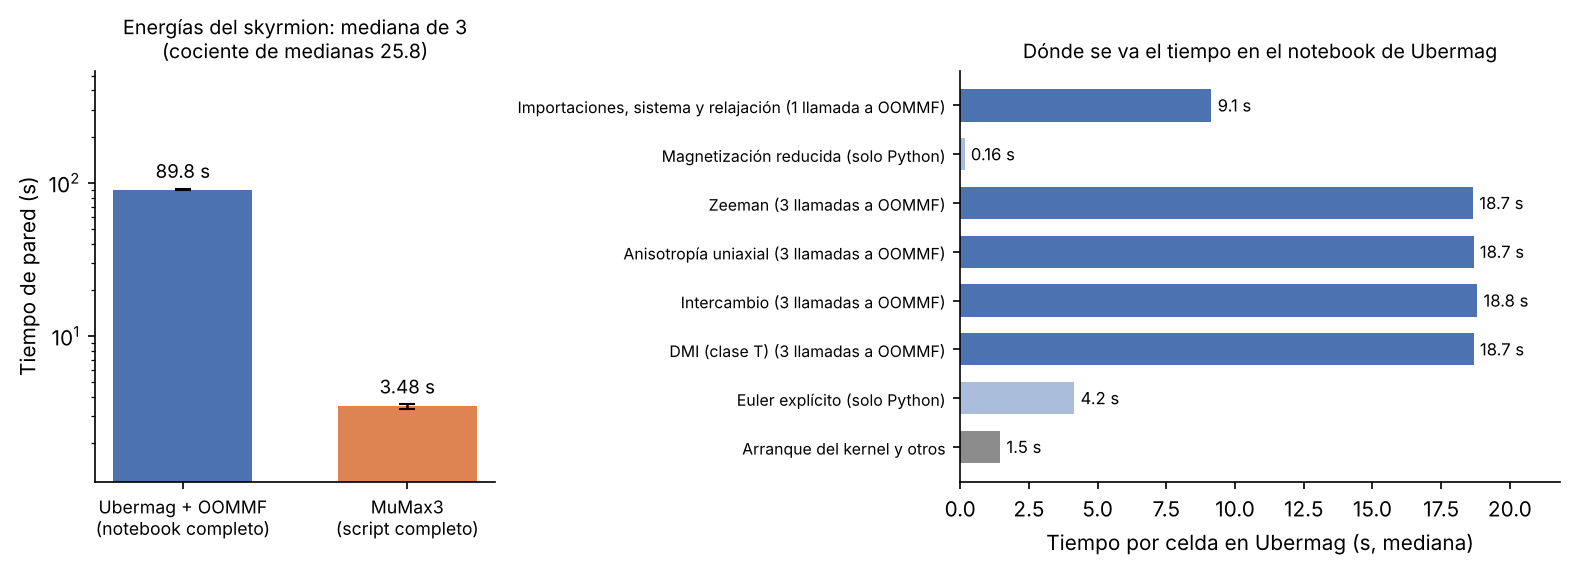

### 8.2 Estados y energías con el mismo modelo

Con `OpenBC=true`, MuMax3 relaja el mismo modelo que OOMMF. La tabla compara las energías (en J) con las referencias de Ubermag; la anisotropía de MuMax3 se muestra convertida a la convención de Ubermag, sumando $K\,V$. El par residual de Ubermag se calculó sobre su estado con los mismos operadores de diferencias finitas.

| Magnitud | Ubermag | MuMax3 (`OpenBC=true`) | Diferencia relativa |
|---|---:|---:|---:|
| Par residual $\max\lvert\mathbf m\times\mathbf B_\mathrm{eff}\rvert$ (T) | $1.2\times10^{-7}$ | $2.1\times10^{-5}$ ($6.6\times10^{-5}$ tras `Run`) | |
| $\langle m_z\rangle$ | $0.42886$ | $0.42886$ | |
| Zeeman | $-1.034722\times10^{-18}$ | $-1.034722\times10^{-18}$ | $3.5\times10^{-7}$ |
| Anisotropía ($K\lvert\mathbf m\times\mathbf u\rvert^2$) | $2.043356\times10^{-19}$ | $2.043356\times10^{-19}$ | $1.7\times10^{-7}$ |
| Intercambio | $1.743837\times10^{-18}$ | $1.743840\times10^{-18}$ | $1.2\times10^{-6}$ |
| DMI | $-4.350588\times10^{-18}$ | $-4.350591\times10^{-18}$ | $6.7\times10^{-7}$ |

El equilibrio simétrico del modelo, calculado en `numpy` en doble precisión, coincide con las referencias de Ubermag a $7\times10^{-8}$ o menos y con su estado a $1.1\times10^{-7}$ celda a celda.

La figura dibuja los estados de los dos códigos con la misma función (mismo mapa de colores, misma escala de $m_z$ y mismas flechas) y, a la derecha, la diferencia $\lvert\mathbf m_\mathrm{MuMax3}-\mathbf m_\mathrm{Ubermag}\rvert$ celda a celda. Los estados son indistinguibles a simple vista.

- **Euler (máximo $8.3\times10^{-8}$).** Con la misma $\gamma_0$ que el notebook (`mm.consts.gamma0` $=2.21276\times10^5$ m A$^{-1}$ s$^{-1}$) y `GammaLL` a la mitad (sección 8.3), los dos Euler coinciden al nivel de la precisión simple de MuMax3. La integración en `numpy` reproduce el estado del notebook a $9\times10^{-10}$ y el de MuMax3 a $8.3\times10^{-8}$ (con 500 pasos de 0.2 ps, a $5.2\times10^{-7}$).
- **Equilibrio (máximo $1.6\times10^{-3}$).** `Relax()` baja el par residual de MuMax3 de $6.6\times10^{-5}$ T a $2.1\times10^{-5}$ T, pero no más, y la diferencia con Ubermag se reparte en cuatro lóbulos alrededor del núcleo. Ese patrón no es el de una relajación incompleta: es el de un modo inestable del skyrmion circular.

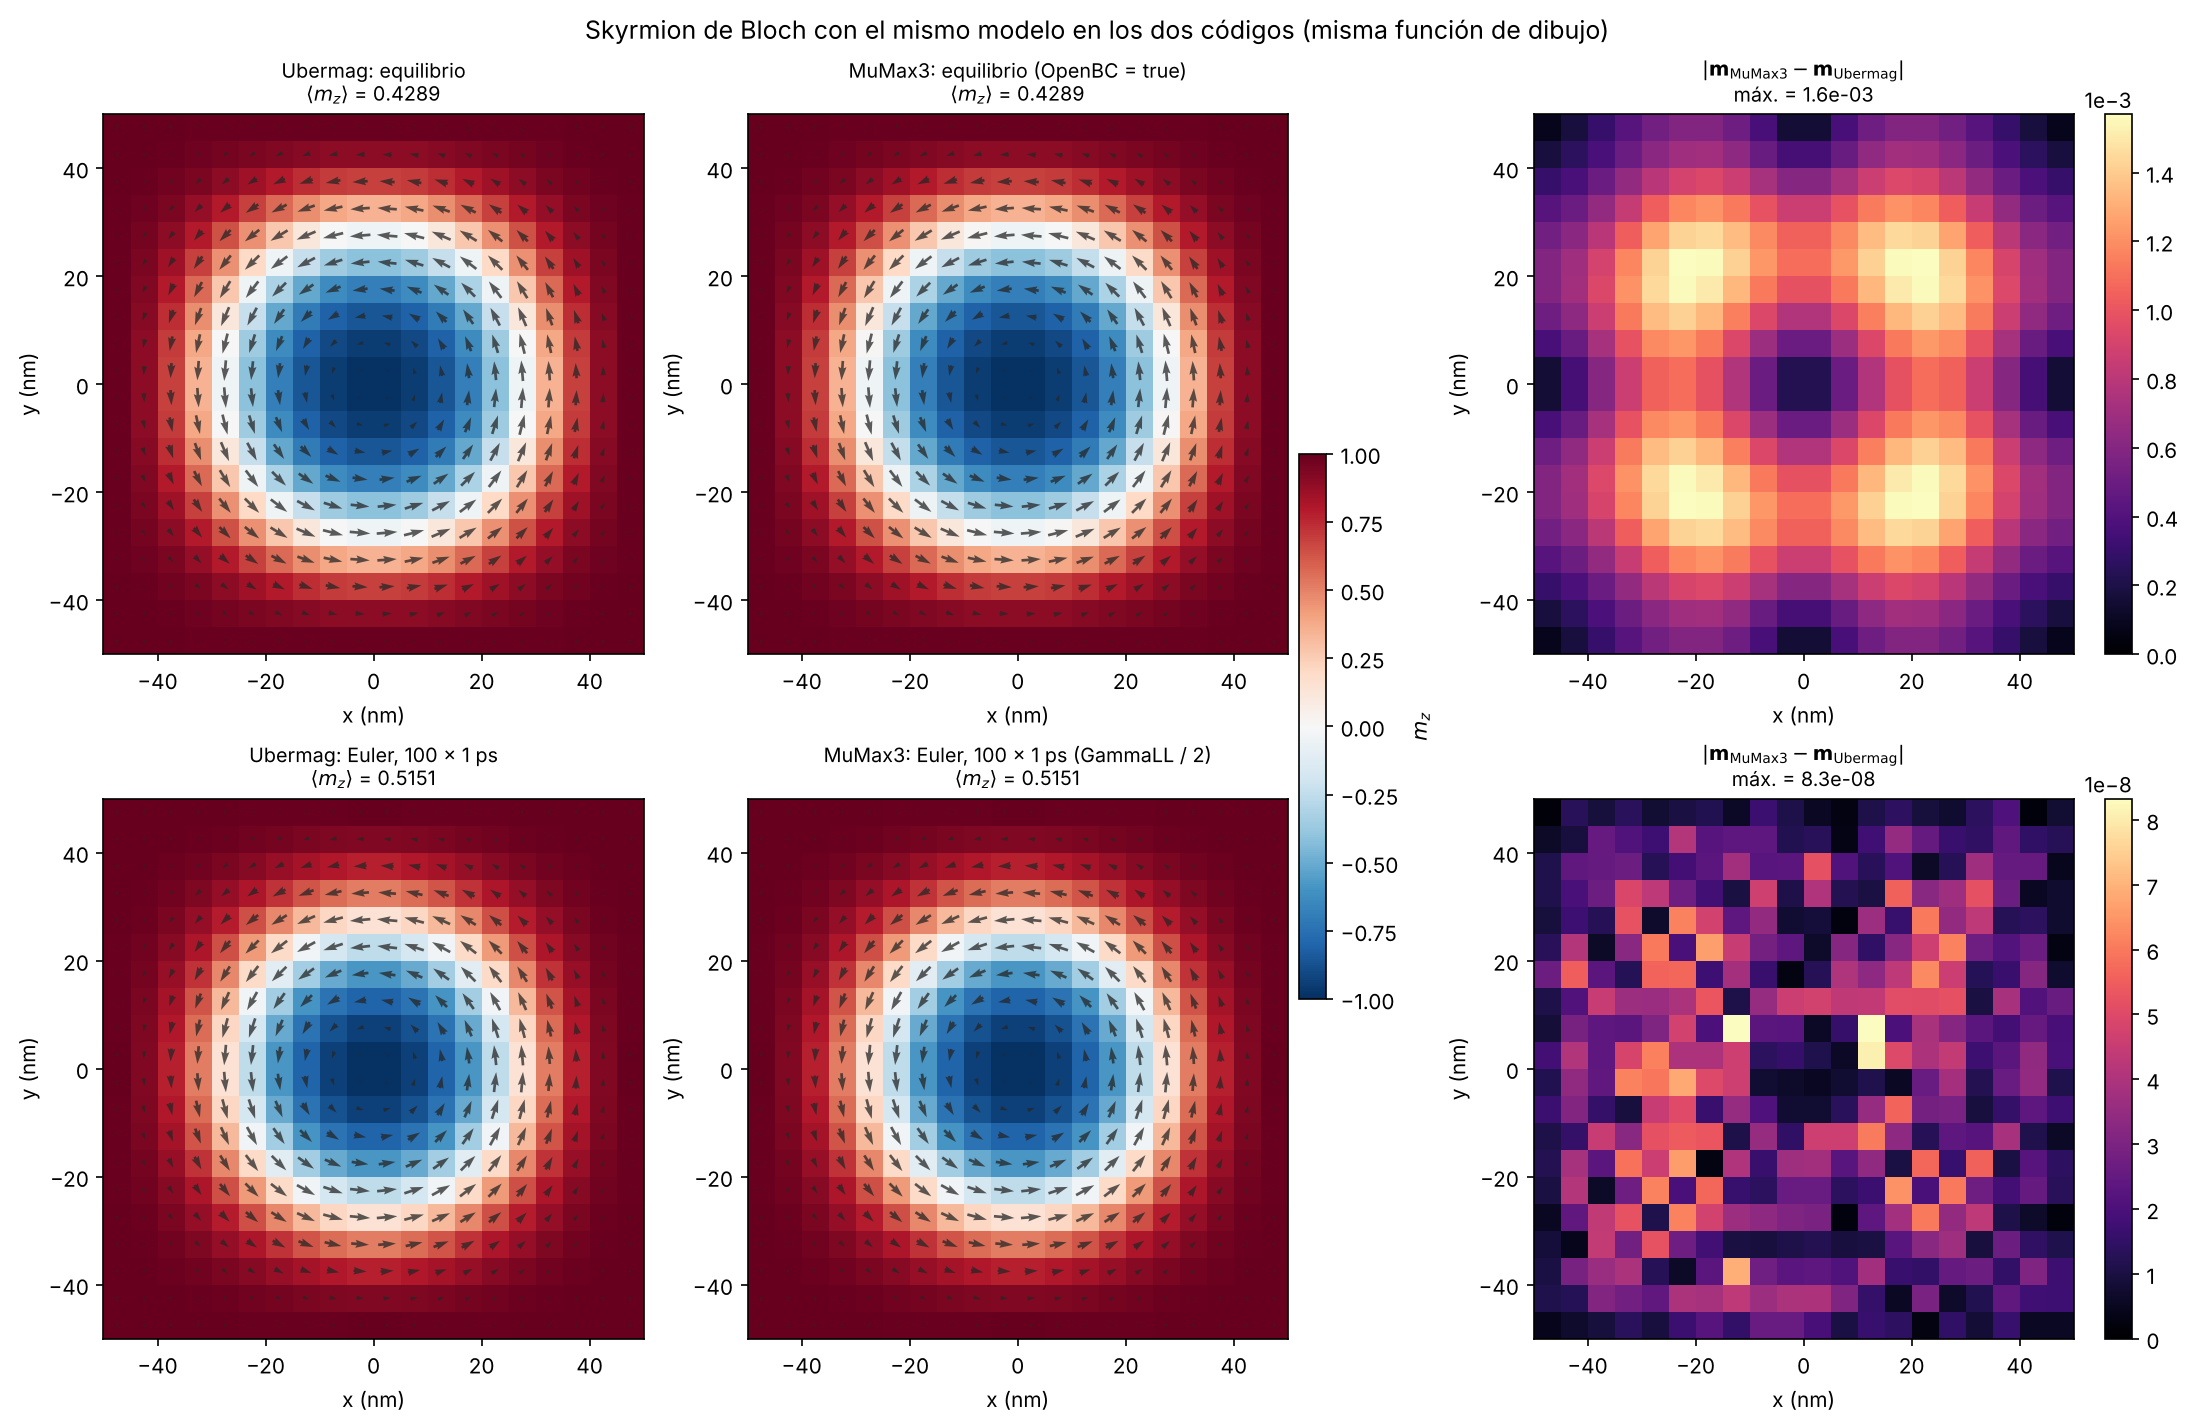

**Estabilidad del skyrmion circular.** El estado relajado de Ubermag tiene la simetría del disco inicial, que la relajación en doble precisión conserva. Si a ese estado se le suma una perturbación aleatoria de amplitud $10^{-9}$ y se deja evolucionar con el torque de amortiguamiento de la sección 6, la perturbación crece en lugar de decaer: su componente a lo largo de un modo cuadrupolar se multiplica por $e$ cada 0.85 ns. El estado simétrico es, por tanto, un punto de silla de la energía y no un mínimo. Siguiendo ese modo, la relajación termina en un skyrmion alargado en una diagonal de la caja, con $\langle m_z\rangle=0.331$, par residual menor que $10^{-13}$ T y una energía $5.0\times10^{-20}$ J (1.5 %) menor que la del estado simétrico: la DMI pasa de $-4.351\times10^{-18}$ a $-5.700\times10^{-18}$ J y compensa el aumento del intercambio ($1.744\times10^{-18}$ a $2.789\times10^{-18}$ J), de la energía de Zeeman y de la anisotropía. Corresponde a la inestabilidad elíptica descrita para skyrmions quirales por debajo de un campo crítico, que los alarga hasta formar bandas helicoidales (Leonov et al., 2016); en esta caja periódica de 100 nm, la banda queda limitada por la diagonal.

MuMax3 calcula en precisión simple, y el redondeo introduce perturbaciones que la relajación amplifica. Con la escala temporal del torque sin precesión de MuMax3 (sección 8.3), `Run(5e-9)` equivale a 11.7 tiempos de crecimiento del modo, un factor de $10^{5}$. La diferencia entre el estado de MuMax3 y el simétrico está entera a lo largo del modo inestable (la fracción de su norma en esa dirección es 1.0000), mientras que la del estado de Ubermag, de $1.1\times10^{-7}$, no tiene componente a lo largo de ese modo. `Relax()` se detiene cuando el par medio deja de disminuir; cerca de un punto de silla, eso ocurre cuando el crecimiento del modo inestable compensa el amortiguamiento de los demás modos, lo que explica que el par residual de MuMax3 no baje de $2.1\times10^{-5}$ T. Las energías apenas cambian porque, cerca del punto de silla, varían con el cuadrado de la desviación: el estado de MuMax3 tiene una energía $1.1\times10^{-25}$ J menor que la del simétrico, una parte en $3\times10^{7}$.

La figura muestra el estado simétrico, la diferencia $m_z(\mathrm{MuMax3})-m_z(\mathrm{simétrico})$, la componente $z$ del modo inestable obtenido en `numpy` y el equilibrio al que lleva ese modo.

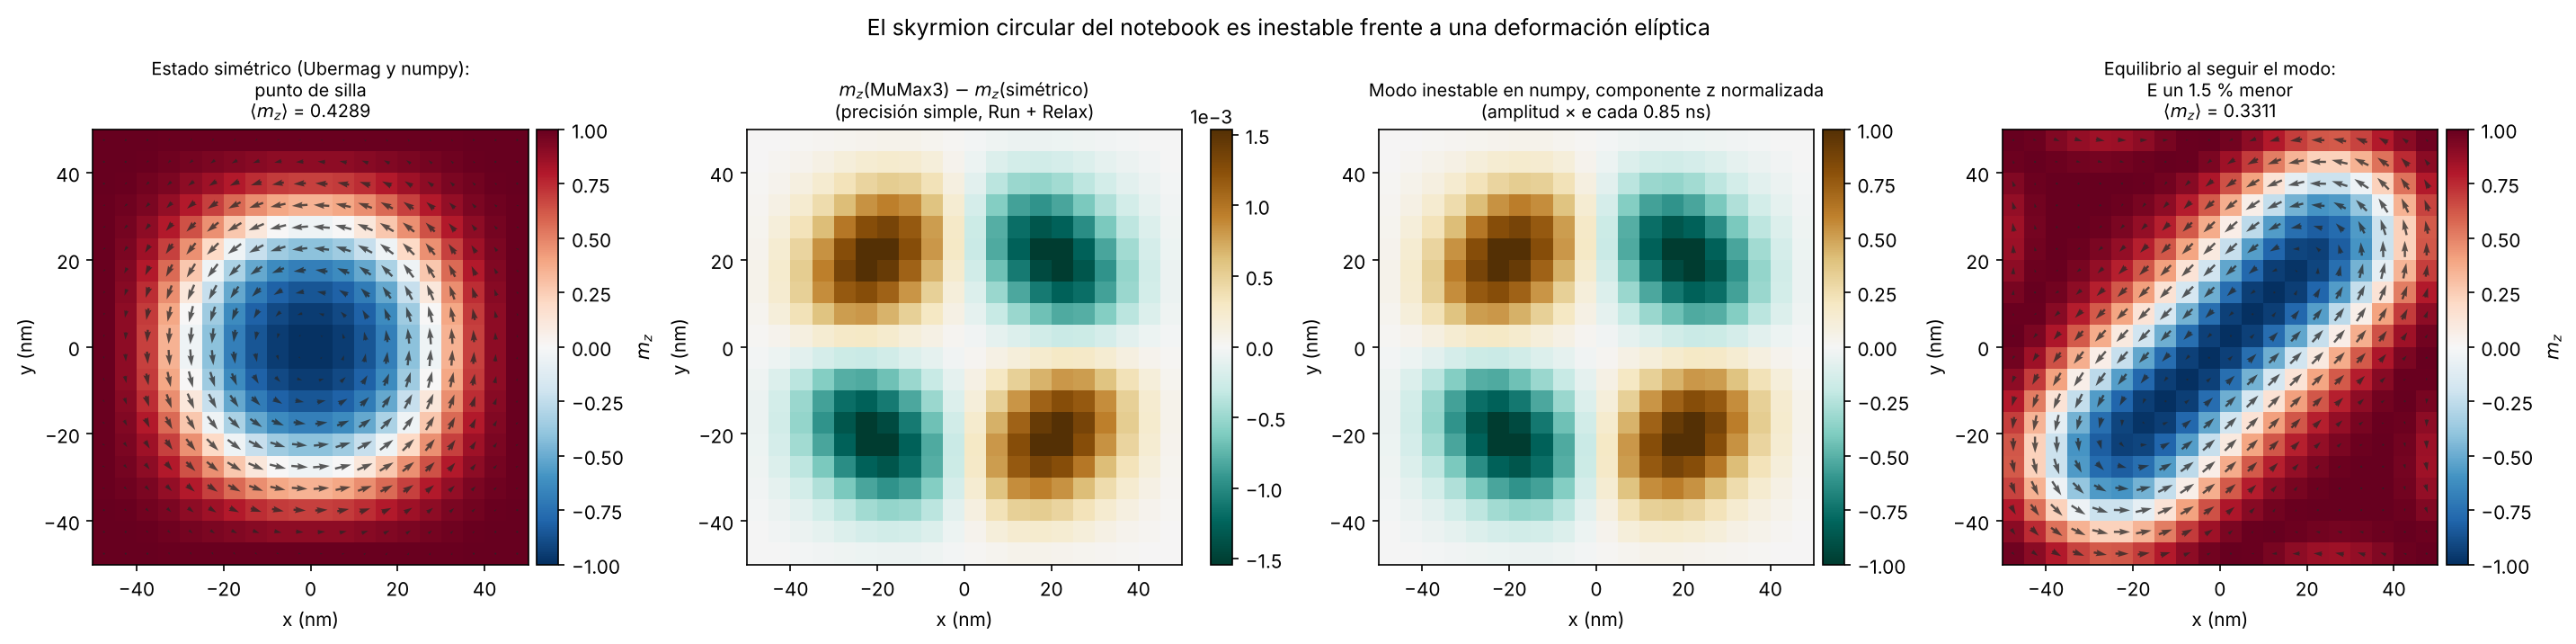

### 8.3 Dinámica sin precesión y estabilidad del Euler

La sección 6 integra el torque de amortiguamiento puro $-\gamma_0\,\alpha/(1+\alpha^2)\,\mathbf m\times(\mathbf m\times\mathbf H_\mathrm{eff})$ con 100 pasos de Euler de 1 ps y estima $\lambda\,\Delta t\approx1.3<2$, un esquema estable. Con `DoPrecess=false`, MuMax3 integra en cambio $-\gamma_0\,\mathbf m\times(\mathbf m\times\mathbf H_\mathrm{eff})$, sin el factor $\alpha/(1+\alpha^2)=1/2$: en el código de MuMax3, la función del torque sin precesión, `LLNoPrecess(torque, m, B)`, no recibe $\alpha$, mientras que la del torque completo, `LLTorque`, sí (Vansteenkiste et al., 2014, ec. 2). La escala temporal del amortiguamiento se duplica y, con el mismo paso, $\lambda\,\Delta t\approx2.6>2$: el Euler de 1 ps se vuelve inestable, y los modos de mayor frecuencia espacial crecen hasta formar una modulación en tablero de ajedrez (sección 8.4).

Para integrar el mismo esquema que el notebook, el script reduce `GammaLL` a la mitad y la calcula con la $\gamma_0$ del notebook. Así, MuMax3 da $\langle m_z\rangle=0.5151$ con 100 pasos de 1 ps, el mismo estado que el notebook con una diferencia máxima de $8.3\times10^{-8}$ por celda (fila inferior de la figura de la sección 8.2), y $0.5155$ con 500 pasos de 0.2 ps, como la integración en `numpy` con ese paso.

### 8.4 Efecto de los ajustes por defecto de MuMax3

**Frontera del DMI.** Como $x$ e $y$ son periódicas, la única frontera libre es $z$, y con una sola celda de espesor la condición de Neumann por defecto de MuMax3 se aplica a toda la película. Imponiendo en las dos caras $\partial_z\mathbf m=(D/2A)\,\hat z\times\mathbf m$ en el término $D\,\mathbf m\cdot(\nabla\times\mathbf m)$ queda un término adicional

$$w_\mathrm{front}=-\frac{D^2}{2A}\,(m_x^2+m_y^2),\qquad \frac{D^2}{2A}=1.42\times10^{5}\ \mathrm{J/m^3},$$

que equivale a una anisotropía uniaxial efectiva $K'=K-D^2/2A=-1.32\times10^{5}$ J/m$^3$: de plano fácil, aunque $K$ sea de eje fácil en $z$. Dos comprobaciones lo confirman:

1. Sobre el estado relajado ($\langle m_x^2+m_y^2\rangle=0.409$), el término vale $-2.905\times10^{-18}$ J y predice una DMI con la frontera de Neumann de $-4.351\times10^{-18}-2.905\times10^{-18}=-7.2555\times10^{-18}$ J, que coincide, con cinco cifras, con la que mide MuMax3 sobre su estado relajado al desactivar `OpenBC` (`energies.txt`).
2. Relajando en `numpy` con $K'$ en lugar de $K$ se obtiene $\langle m_z\rangle=0.2277$ y energías de Zeeman, anisotropía, intercambio y DMI (con el término de frontera) de $-5.494\times10^{-19}$, $3.445\times10^{-19}$, $2.168\times10^{-18}$ y $-9.389\times10^{-18}$ J. El script `skyrmion_default_settings_mumax3.mx3`, que relaja en MuMax3 con la frontera por defecto, llega al mismo estado: $\langle m_z\rangle=0.22771$, diferencia máxima de $1.6\times10^{-6}$ por celda con la réplica en `numpy`, par residual de $3.1\times10^{-7}$ T y las cuatro energías iguales a $1.2\times10^{-7}$ o menos.

A diferencia del estado de la sección 8.2, este equilibrio es estable: una perturbación aleatoria de $10^{-9}$ no crece en 12 ns de la dinámica de la sección 6 (`scripts/skyrmion_instability_numpy.py`). Es el equilibrio de otro modelo, no un error numérico: la frontera de Neumann describe una superficie libre con DMI, que OOMMF no incluye. Para comparar con Ubermag hay que usar `OpenBC=true` desde el inicio de la relajación, y no solo al leer la energía.

**Torque sin precesión.** Con `GammaLL` sin modificar, el Euler de 1 ps de la sección 6 cae en la región inestable ($\lambda\,\Delta t\approx2.6$). Con la frontera por defecto y `GammaLL` sin modificar, MuMax3 termina en $\langle m_z\rangle=0.2487$, con la modulación en tablero de ajedrez superpuesta al skyrmion, y la réplica en `numpy` de ese esquema da el mismo estado con una diferencia máxima de $2.8\times10^{-7}$ por celda; con el factor $1/2$ del notebook, el resultado difiere de este en hasta $0.43$ por celda. Con un paso de 0.2 ps el mismo esquema vuelve a ser estable y llega al equilibrio del modelo de Neumann ($\langle m_z\rangle=0.2277$).

La figura muestra los dos casos, calculados en MuMax3, junto al estado con `OpenBC=true`.

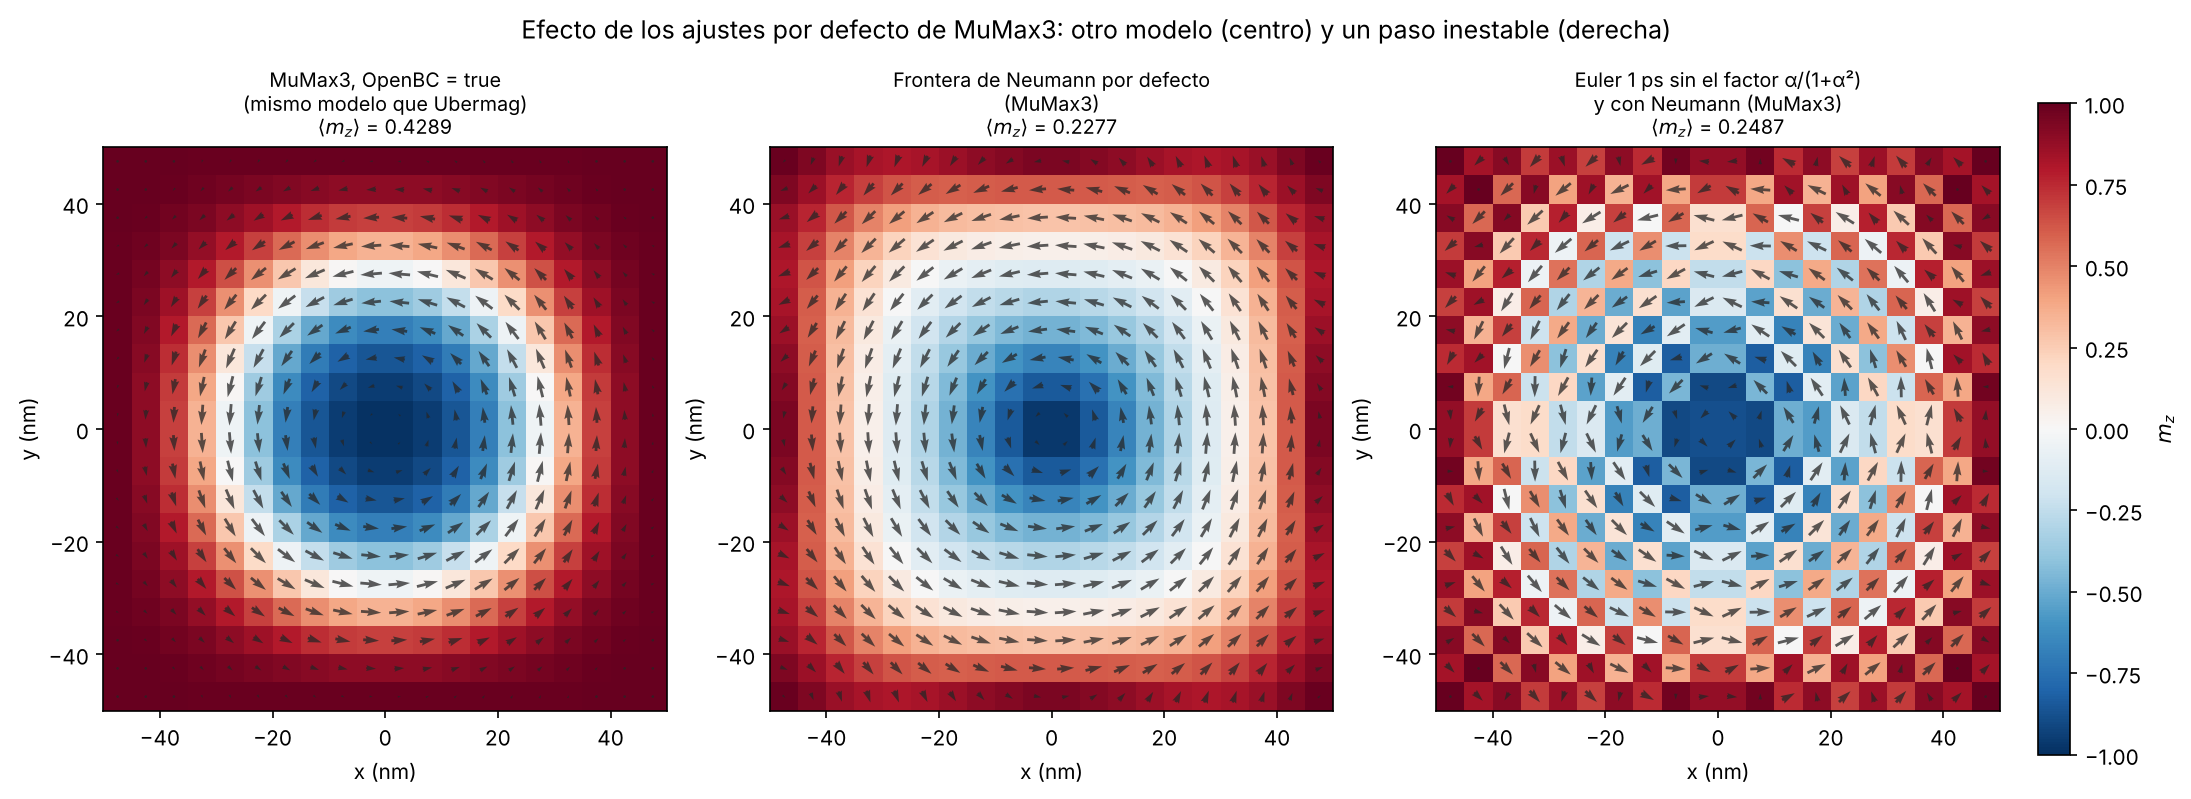

**Relajación.** MuMax3 ofrece también `Minimize()`, un descenso de gradiente (Exl et al., 2014) que se detiene cuando el cambio máximo de $\mathbf m$ entre iteraciones es menor que `MinimizerStop` ($10^{-6}$ por defecto), un criterio que mide el avance entre iteraciones y no el par residual. En una prueba con este mismo problema, `Minimize()` se detuvo en un estado con un par residual de 0.37 T, del orden del campo aplicado, lejos de un mínimo; por eso el script relaja con dinámica amortiguada y `Relax()`. En cualquier caso, conviene imprimir `MaxTorque` tras relajar y no dar por convergido un estado solo porque la instrucción terminó sin error.

### 8.5 Conclusiones de la comparación

1. **MuMax3 reproduce el resultado de Ubermag cuando se configura el mismo modelo.** Con `OpenBC=true` desde la relajación y `GammaLL` a la mitad, calculada con la misma $\gamma_0$, las cuatro energías coinciden con las de Ubermag con diferencias relativas de $1.2\times10^{-6}$ o menos, el estado relajado tiene $\langle m_z\rangle=0.42886$ y los estados del Euler coinciden a $8.3\times10^{-8}$ por celda, el nivel de la precisión simple (secciones 8.2 y 8.3).
2. **El skyrmion circular del ejemplo es un punto de silla.** Frente a una deformación elíptica, el estado simétrico es inestable: el modo crece por un factor $e$ cada 0.85 ns y lleva a un skyrmion alargado con una energía un 1.5 % menor. OOMMF, que parte de un estado simétrico, calcula en doble precisión y se detiene con un par residual de 0.1 A/m, queda en el punto de silla. MuMax3, en precisión simple, se aparta de él a lo largo del modo inestable: de ahí la diferencia de $1.6\times10^{-3}$ entre los estados y un par residual que no baja de $2.1\times10^{-5}$ T (sección 8.2).
3. **Los ajustes por defecto de MuMax3 definen otro modelo.** La frontera de Neumann del DMI añade $-D^2/2A\,(m_x^2+m_y^2)$ en una película de una celda y cambia el equilibrio, que MuMax3 alcanza en $\langle m_z\rangle=0.2277$. Es un efecto físico de las superficies libres que OOMMF no incluye.
4. **La escala temporal del torque sin precesión es distinta.** Con `DoPrecess=false` no aparece el factor $\alpha/(1+\alpha^2)$, y un Euler estable en el notebook es inestable en MuMax3.
5. **Comparar códigos exige comparar estados, constantes y estabilidad.** Antes de comparar energías hay que comprobar el equilibrio (par residual, `MaxTorque`), que ambos resuelven el mismo modelo y que usan las mismas constantes. Un par residual que no baja aunque se relaje más no indica por sí solo un criterio de parada insuficiente: aquí indica un equilibrio inestable. Una figura que mostrara solo los resultados con los ajustes por defecto atribuiría a MuMax3 diferencias que son de configuración.
6. **Los tiempos dependen del flujo de trabajo.** Con el script de MuMax3 (3.48 s) y el notebook de Ubermag (89.76 s) el cociente de medianas es 25.8, pero el 94 % del tiempo de Ubermag son 13 llamadas a OOMMF de unos 6.2 s cada una, de los que unos 6.15 s son un costo fijo independiente del tamaño del problema (sección 8.1). La cifra describe el flujo de trabajo en esta máquina, no la velocidad de los solvers.

**Niveles de equivalencia entre las dos implementaciones**

| Nivel | ¿Equivalentes? | Observación |
|---|---|---|
| Física | Sí, con `OpenBC=true` | Con la frontera por defecto de MuMax3 el modelo es otro (sección 8.4). |
| Discretización | Sí | Misma malla de $20\times20\times1$ celdas de 5 nm, periódica en $x$ e $y$, con derivadas por diferencias centrales. |
| Numérica | Parcial | Distinto algoritmo y precisión: OOMMF (CPU, doble precisión) minimiza hasta $\lvert\mathbf m\times\mathbf H\rvert<0.1$ A/m (valor por defecto de `oommfc` 0.66.0) y queda en el punto de silla simétrico; MuMax3 (GPU, precisión simple) integra 5 ns de dinámica amortiguada, sigue con `Relax()` y se aparta del punto de silla a lo largo del modo inestable. Las energías coinciden a $1.2\times10^{-6}$, los estados de equilibrio a $1.6\times10^{-3}$ y los del Euler a $8.3\times10^{-8}$. |
| Observables | Sí | Mismas energías por término (con la conversión $K\,V$ de la anisotropía) y mismo $\langle m_z\rangle$. |

## Referencias

**Fuentes académicas**

Aharoni, A. (2000). *Introduction to the theory of ferromagnetism* (2.ª ed.). Oxford University Press.

Bak, P., & Jensen, M. H. (1980). Theory of helical magnetic structures and phase transitions in MnSi and FeGe. *Journal of Physics C: Solid State Physics, 13*(31), L881-L885.

Beg, M., Lang, M., & Fangohr, H. (2022). Ubermag: Toward more effective micromagnetic workflows. *IEEE Transactions on Magnetics, 58*(2), 1-5. https://doi.org/10.1109/TMAG.2021.3078896

Bogdanov, A., & Hubert, A. (1994). Thermodynamically stable magnetic vortex states in magnetic crystals. *Journal of Magnetism and Magnetic Materials, 138*(3), 255-269.

Brown, W. F. (1963). *Micromagnetics*. Interscience Publishers.

Donahue, M. J., & Porter, D. G. (1999). *OOMMF user's guide, version 1.0* (NISTIR 6376). National Institute of Standards and Technology. https://doi.org/10.6028/NIST.IR.6376

Dzyaloshinsky, I. (1958). A thermodynamic theory of "weak" ferromagnetism of antiferromagnetics. *Journal of Physics and Chemistry of Solids, 4*(4), 241-255.

Exl, L., Bance, S., Reichel, F., Schrefl, T., Peter Stimming, H., & Mauser, N. J. (2014). LaBonte's method revisited: An effective steepest descent method for micromagnetic energy minimization. *Journal of Applied Physics, 115*(17), 17D118. https://doi.org/10.1063/1.4862839

Gilbert, T. L. (2004). A phenomenological theory of damping in ferromagnetic materials. *IEEE Transactions on Magnetics, 40*(6), 3443-3449.

Holt, S. J. R., Lang, M., Loudon, J. C., Hicken, T. J., Suess, D., Cortés-Ortuño, D., Pathak, S. A., Beg, M., Zulfiqar, K., & Fangohr, H. (2025). Virtual experiments in computational magnetism with mag2exp. *npj Computational Materials, 11*, 201. https://doi.org/10.1038/s41524-025-01686-3

Landau, L. D., & Lifshitz, E. M. (1935). On the theory of the dispersion of magnetic permeability in ferromagnetic bodies. *Physikalische Zeitschrift der Sowjetunion, 8*, 153-169.

Leonov, A. O., Monchesky, T. L., Romming, N., Kubetzka, A., Bogdanov, A. N., & Wiesendanger, R. (2016). The properties of isolated chiral skyrmions in thin magnetic films. *New Journal of Physics, 18*(6), 065003. https://doi.org/10.1088/1367-2630/18/6/065003

Moriya, T. (1960). Anisotropic superexchange interaction and weak ferromagnetism. *Physical Review, 120*(1), 91-98.

Mühlbauer, S., Binz, B., Jonietz, F., Pfleiderer, C., Rosch, A., Neubauer, A., Georgii, R., & Böni, P. (2009). Skyrmion lattice in a chiral magnet. *Science, 323*(5916), 915-919.

Rößler, U. K., Bogdanov, A. N., & Pfleiderer, C. (2006). Spontaneous skyrmion ground states in magnetic metals. *Nature, 442*, 797-801. https://doi.org/10.1038/nature05056

Tiesinga, E., Mohr, P. J., Newell, D. B., & Taylor, B. N. (2021). CODATA recommended values of the fundamental physical constants: 2018. *Reviews of Modern Physics, 93*(2), 025010. https://doi.org/10.1103/RevModPhys.93.025010

Vansteenkiste, A., Leliaert, J., Dvornik, M., Helsen, M., Garcia-Sanchez, F., & Van Waeyenberge, B. (2014). The design and verification of MuMax3. *AIP Advances, 4*(10), 107133. https://doi.org/10.1063/1.4899186

**Fuentes complementarias**

Ubermag developers. (s. f.). *Field operations 2*. Ubermag documentation. https://ubermag.github.io/examples/notebooks/field-operations2.html

MuMax3 developers. (s. f.). *mumax3 API*. https://mumax.github.io/api.html

MuMax3 developers. (s. f.). *mumax/3* [Código fuente]. GitHub. https://github.com/mumax/3

OOMMF Documentation Team. (2023). *OOMMF programming manual: OOMMF variable types and macros*. National Institute of Standards and Technology. https://math.nist.gov/oommf/doc/progman21a0/progman/OOMMF_Variable_Types_Macros.html

Ubermag developers. (s. f.). *oommfc* (versión 0.66.0) [Código fuente]. GitHub. https://github.com/ubermag/oommfc